# 01. EDA raw_data: ??????, ??????????? ? ???????????

**????.** ?????????, ??? ?????? ??????? ?????????????? ???????? ?? ????? ????? ? KPI, ? ?? ?? ??????? ?????????????? ??????. ?? ???? ????? ??????????? ?????? ????????? ??????, ???????? ???????????? ? ???????????, ??????? ?????? ????????? baseline ? ??????.

**?????????.** ???????????? ???????? ??????? ?????? ?????????? ??????? ? `raw_data/`. ??? ??????????? ????????? ????? ????? ? `dashboard/artifacts/`.


In [1]:
from pathlib import Path
import json
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from dashboard.final_data_pipeline import PROJECT_ROOT, SEED, scan_raw_data, write_json

random.seed(SEED)
np.random.seed(SEED)
RAW_DATA = PROJECT_ROOT / "raw_data"
ARTIFACT_DIR = PROJECT_ROOT / "dashboard" / "artifacts"
REPORT_DIR = ARTIFACT_DIR / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print(f"raw_data: {RAW_DATA}")
print(f"artifact_dir: {ARTIFACT_DIR}")


raw_data: C:\Main\DGTU\ВКР\Diploma\raw_data
artifact_dir: C:\Main\DGTU\ВКР\Diploma\dashboard\artifacts


## 1. ?????????? ??????

??????? ?????? ????????? ?? ???????? workload ?? ??????? ? ????????? ?????????????? ?? ???????????? ????. ??????? ???????? ??????? ?? ????? ??????? ????????????? ????????? ?????? ????: ??????? ?????? ????????? ????????? ????, ??????????? ????? ? KPI, ?????????? ?? ??????? ? ???? ?????? ????? ??????? ??????? ????????.


In [2]:
inventory, issues = scan_raw_data(RAW_DATA)
summary = (
    inventory.groupby(["pair_status", "scenario_type"], dropna=False)
    .agg(runs=("run_id", "nunique"), workloads=("workload", "nunique"))
    .reset_index()
)
display(summary)


,pair_status,scenario_type,runs,workloads
0,KPI_ONLY,normal,7,1
1,LOG_ONLY,normal,2,2
2,MISSING,failure,5,5
3,STRICT,failure,352,16
4,STRICT,normal,88,15


**????????? ?????.** ???????? ????????? ?????? ?????? ????? ?????? ???? `STRICT`, ??? ???? ? raw log, ? KPI. ???????? ???????? ????? ??? ????? ????????, ?? ??? ?? ?????? ????????? ???????? ? supervised training.


## 2. ???????? ????????????

????????? ????????????? ???????? ?? workload ? ????? ?????????. ??? ????? ??? split: ??????? ???????? ?????? workload ?????? ???????? ????????? ????? train ? test.


scenario_type,workload,failure,normal,total
0,aggregation,22,7,29
3,graph_pagerank,22,7,29
4,join,22,7,29
15,wordcount,22,7,29
11,sort,22,7,29
10,sleep,22,7,29
9,scan,22,7,29
8,rf,22,7,29
7,repartition,22,6,28
13,terasort,22,6,28


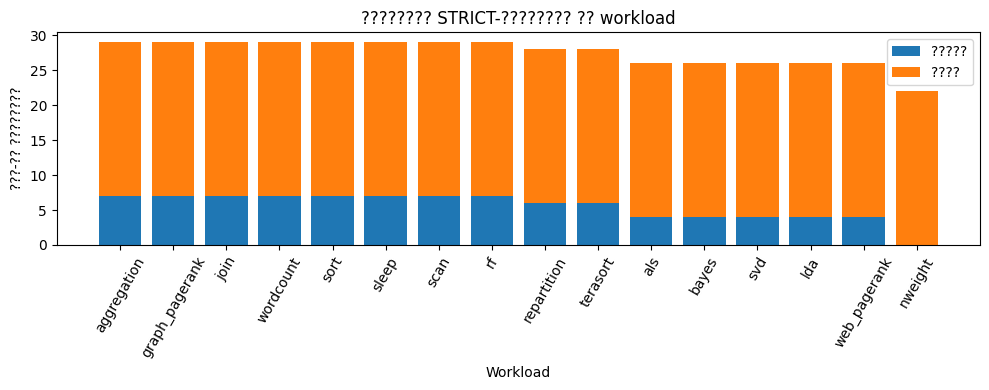

In [3]:
strict = inventory.loc[inventory["pair_status"].eq("STRICT")].copy()
workload_summary = (
    strict.groupby(["workload", "scenario_type"])["run_id"]
    .nunique()
    .unstack(fill_value=0)
    .reset_index()
)
workload_summary["total"] = workload_summary.drop(columns=["workload"]).sum(axis=1)
display(workload_summary.sort_values("total", ascending=False).head(20))

fig, ax = plt.subplots(figsize=(10, 4))
plot_data = workload_summary.sort_values("total", ascending=False)
ax.bar(plot_data["workload"], plot_data.get("normal", 0), label="?????")
ax.bar(plot_data["workload"], plot_data.get("failure", 0), bottom=plot_data.get("normal", 0), label="????")
ax.set_title("???????? STRICT-???????? ?? workload")
ax.set_ylabel("???-?? ????????")
ax.set_xlabel("Workload")
ax.tick_params(axis="x", rotation=60)
ax.legend()
plt.tight_layout()
plt.show()


**??? ????????.** ?????????? ???????? ? ????? ????????????? ?? workload.  
**??? ???????????.** ?????? ????????????? ?? ????????????? workload ? ????????? ??????.  
**????????? ?????.** Split ?????? ???? workload/run-aware, ????? ?????? ????? ????????? ??????????? ??????????? workload ?????? ??????? ??????? ??????????.


## 3. ??????????? ??????

????????? ???????? ?????? ???? ????????? ?????? ???????????: ?????????????? ????? ? KPI, ???????? ????????????, ????????? ??????? ???? ? ???? ??????? ??????? ??????. ??????? ????????? ???? ?????? ??????? ???? ? `gap10`: ?????? ?? ????? ?????? ??????? ? ???????? ?????? ?????????????? ????????.


In [4]:
issue_summary = issues.groupby("issue").size().reset_index(name="count") if not issues.empty else pd.DataFrame(columns=["issue", "count"])
display(issue_summary)

eda_payload = {
    "raw_data": str(RAW_DATA.relative_to(PROJECT_ROOT)),
    "strict_runs": int(strict["run_id"].nunique()),
    "workloads": int(strict["workload"].nunique()),
    "normal_runs": int(strict.loc[strict["scenario_type"].eq("normal"), "run_id"].nunique()),
    "failure_runs": int(strict.loc[strict["scenario_type"].eq("failure"), "run_id"].nunique()),
    "non_strict_issues": issue_summary.to_dict("records"),
}
write_json(REPORT_DIR / "01_eda_summary.json", eda_payload)
print("????????:", (REPORT_DIR / "01_eda_summary.json").relative_to(PROJECT_ROOT))


,issue,count
0,KPI measurements without mapred log,7
1,mapred log without KPI measurements,2


????????: dashboard\artifacts\reports\01_eda_summary.json


**Handoff ? 02.** ????????? ??????? ?????? ?? `raw_data/` ??????? window-contract: ????????? ????? `10s`, ???????? ????? `60s`, KPI-????????, `strict_lead_sec`, `warning/risk intensity`, split ? baseline.
